In [1]:
import sys
from pathlib import Path

project_root = Path("..").resolve()

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# ==========================================
# StyleMatch AI - Startup / Resume Cell
# ==========================================

import sys
from pathlib import Path

import torch
import numpy as np
import pandas as pd

from transformers import CLIPModel, CLIPProcessor


# 1. Add project root so notebook can find src/
project_root = Path("..").resolve()

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))


# 2. Import our reusable search functions
from src.search_engine import (
    search_products,
    search_by_image,
    show_search_results
)


# 3. Select CPU / GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# 4. Load CLIP
model_name = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(
    model_name
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    model_name
)

clip_model.eval()

print("CLIP loaded")


# 5. Load saved 10,000 product embeddings
image_embeddings_10000 = np.load(
    "../embeddings/image_embeddings_10000.npy"
)

df_products_10000 = pd.read_csv(
    "../embeddings/products_10000.csv"
)

print("Embeddings:", image_embeddings_10000.shape)
print("Products:", len(df_products_10000))

print("\nStyleMatch AI is ready!")

Device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded
Embeddings: (10000, 512)
Products: 10000

StyleMatch AI is ready!


In [4]:
from src.search_engine import (
    search_products,
    search_products_filtered,
    search_by_image,
    show_search_results
)

print("Search functions imported successfully")

Search functions imported successfully


In [2]:
import pandas as pd
from pathlib import Path

data_path = Path("../data")
images_path = data_path/"images"
csv_path = data_path/"styles.csv" 
df = pd.read_csv(
    csv_path,
    on_bad_lines="skip"
)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [3]:
print("Columns:")

for column in df.columns:
    print(column)

Columns:
id
gender
masterCategory
subCategory
articleType
baseColour
season
year
usage
productDisplayName


In [4]:
df["image_path"] = df["id"].apply(
    lambda x: images_path/ f"{x}.jpg"
)

df["image_exists"] = df["image_path"].apply(
    lambda x: x.exists()
)

print("Products in CSV:", len(df))
print("Images found:",df["image_exists"].sum())
print("Missing Images:", (~df["image_exists"]).sum())

Products in CSV: 44424
Images found: 44419
Missing Images: 5


In [5]:
df_clean = df[
    df["image_exists"]
].copy()

print("Usable products:", len(df_clean))

Usable products: 44419


In [6]:
print("Master Categories:")
print(df_clean["masterCategory"].value_counts())

print("\nTop15 Article Types:")
print(df_clean["articleType"].value_counts().head(15))

print("\nTop 15 Colours:")
print(df_clean["baseColour"].value_counts().head(15))

Master Categories:
masterCategory
Apparel           21392
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64

Top15 Article Types:
articleType
Tshirts         7066
Shirts          3215
Casual Shoes    2845
Watches         2542
Sports Shoes    2036
Kurtas          1844
Tops            1762
Handbags        1759
Heels           1323
Sunglasses      1073
Wallets          936
Flip Flops       914
Sandals          897
Briefs           849
Belts            813
Name: count, dtype: int64

Top 15 Colours:
baseColour
Black        9727
White        5538
Blue         4917
Brown        3494
Grey         2741
Red          2453
Green        2115
Pink         1860
Navy Blue    1789
Purple       1640
Silver       1090
Yellow        778
Beige         749
Gold          628
Maroon        581
Name: count, dtype: int64


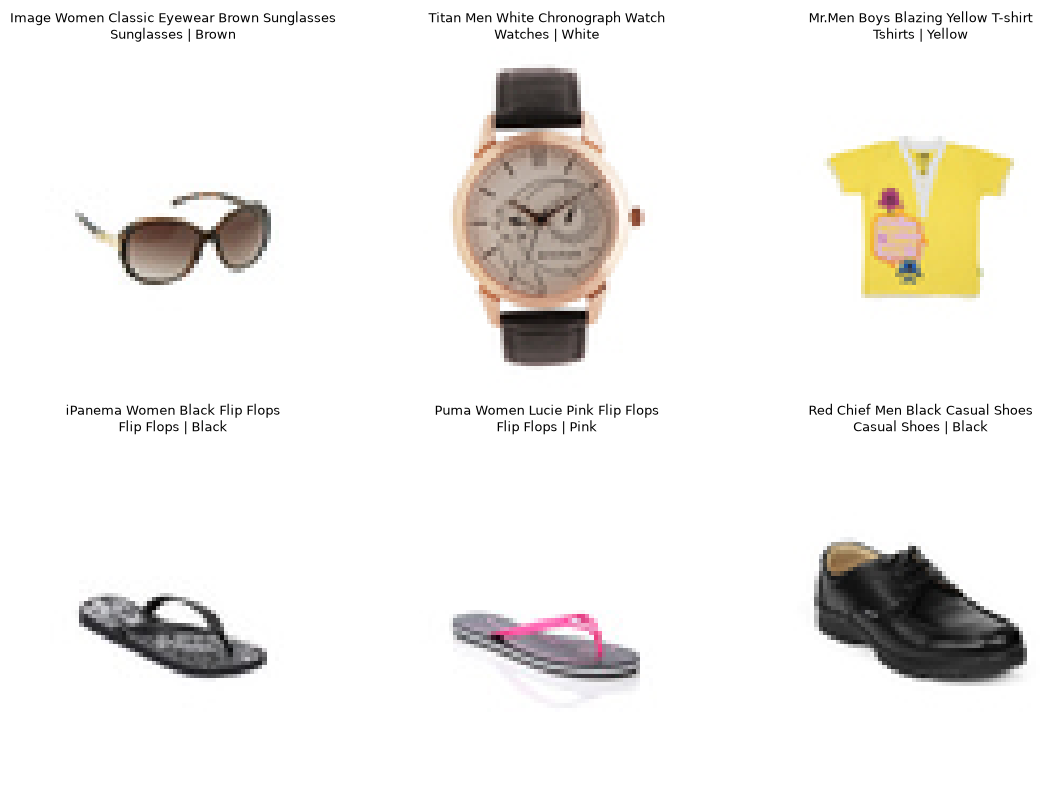

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

samples = df_clean.sample(
    6,
    random_state=42
)

plt.figure(figsize=(12,8))

for i, (_, row) in enumerate(samples.iterrows()):
    image = Image.open(
        row["image_path"]
    ).convert("RGB")

    plt.subplot(2,3, i+1)
    plt.imshow(image)

    plt.title(
        f"{row['productDisplayName']}\n"
        f"{row['articleType']} | {row['baseColour']}",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
important_columns = [
    "id",
    "gender",
    "masterCategory",
    "subCategory",
    "articleType",
    "baseColour",
    "season",
    "usage",
    "productDisplayName",
    "image_path"
]

df_products = df_clean[
    important_columns
].copy()

print("Usable products:", len(df_products))

df_products.head()

Usable products: 44419


,id,gender,masterCategory,subCategory,articleType,baseColour,season,usage,productDisplayName,image_path
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,Casual,Turtle Check Men Navy Blue Shirt,..\data\images\15970.jpg
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,Casual,Peter England Men Party Blue Jeans,..\data\images\39386.jpg
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,Casual,Titan Women Silver Watch,..\data\images\59263.jpg
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,Casual,Manchester United Men Solid Black Track Pants,..\data\images\21379.jpg
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,Casual,Puma Men Grey T-shirt,..\data\images\53759.jpg


In [9]:
print(
    df_products.isnull().sum()
)

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
usage                 317
productDisplayName      7
image_path              0
dtype: int64


In [10]:
def create_product_text(row):

    parts = [
        str(row["productDisplayName"]),
        str(row["gender"]),
        str(row["masterCategory"]),
        str(row["subCategory"]),
        str(row["articleType"]),
        str(row["baseColour"]),
        str(row["usage"])
    ]

    parts = [
        part
        for part in parts
        if part.lower() != "nan"
    ]

    return " ".join(parts)


df_products["product_text"] = df_products.apply(
    create_product_text,
    axis=1
)

df_products[
    [
        "productDisplayName",
        "product_text"
    ]
].head()

,productDisplayName,product_text
0,Turtle Check Men Navy Blue Shirt,Turtle Check Men Navy Blue Shirt Men Apparel T...
1,Peter England Men Party Blue Jeans,Peter England Men Party Blue Jeans Men Apparel...
2,Titan Women Silver Watch,Titan Women Silver Watch Women Accessories Wat...
3,Manchester United Men Solid Black Track Pants,Manchester United Men Solid Black Track Pants ...
4,Puma Men Grey T-shirt,Puma Men Grey T-shirt Men Apparel Topwear Tshi...


In [11]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_name = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(
    model_name
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    model_name
)

clip_model.eval()

print("Device:", device)
print("CLIP loaded successfully")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Device: cpu
CLIP loaded successfully


In [12]:
import pandas as pd
from pathlib import Path
from PIL import Image

data_path = Path("../data")
images_path = data_path / "images"
csv_path = data_path / "styles.csv"

df = pd.read_csv(
    csv_path,
    on_bad_lines="skip"
)

df["image_path"] = df["id"].apply(
    lambda x: images_path / f"{x}.jpg"
)

df["image_exists"] = df["image_path"].apply(
    lambda x: x.exists()
)

df_clean = df[df["image_exists"]].copy()

important_columns = [
    "id",
    "gender",
    "masterCategory",
    "subCategory",
    "articleType",
    "baseColour",
    "season",
    "usage",
    "productDisplayName",
    "image_path"
]

df_products = df_clean[
    important_columns
].copy()

print("Usable products:", len(df_products))

Usable products: 44419


Product: Turtle Check Men Navy Blue Shirt


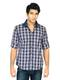

In [13]:
sample_row = df_products.iloc[0]

sample_image = Image.open(
    sample_row["image_path"]
).convert("RGB")

print("Product:", sample_row["productDisplayName"])

sample_image

In [14]:
inputs = clip_processor(
    images=sample_image,
    return_tensors ="pt" 
)

pixel_values = inputs["pixel_values"].to(device)
print("Pixel tensor shape:", pixel_values.shape)

Pixel tensor shape: torch.Size([1, 3, 224, 224])


In [15]:
with torch.inference_mode():

    vision_outputs = clip_model.vision_model(
        pixel_values=pixel_values
    )

    pooled_output = vision_outputs.pooler_output

    image_embedding = clip_model.visual_projection(
        pooled_output
    )

print("Embedding shape:", image_embedding.shape)

Embedding shape: torch.Size([1, 512])


In [16]:
image_embedding = image_embedding / image_embedding.norm(
    dim=-1,
    keepdim=True
)
print("Embedding norm:", image_embedding.norm().item())

Embedding norm: 1.0


In [17]:
text_options=[
    "a navy blue check shirt",
    "a pair of black shoes",
    "a wrist watch",
    "a pair of sunglasses"
]

In [18]:
text_inputs = clip_processor(
    text=text_options,
    padding=True,
    return_tensors="pt" 
)

input_ids = text_inputs["input_ids"].to(device)
attention_mask = text_inputs["attention_mask"].to(device)

In [19]:
with torch.inference_mode():
    text_outputs = clip_model.text_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    pooled_text = text_outputs.pooler_output

    text_embeddings = clip_model.text_projection(
        pooled_text
    )

    text_embeddings = text_embeddings / text_embeddings.norm(
        dim=-1,
        keepdim=True
    )

In [20]:
similarities = image_embedding @ text_embeddings.T

for text, score in zip(
    text_options,
    similarities[0].tolist()
):
    print(f"{text}: {score:.4f}")

a navy blue check shirt: 0.2890
a pair of black shoes: 0.1629
a wrist watch: 0.1810
a pair of sunglasses: 0.1684


In [21]:
df_subset = df_products.sample(
    n=1000,
    random_state=42
).reset_index(drop=True)

print("Products in test catalog:", len(df_subset))

Products in test catalog: 1000


In [22]:
import numpy as np
from tqdm.auto import tqdm

batch_size = 32

all_image_embeddings = []
valid_indices = []

for start in tqdm(
    range(0, len(df_subset), batch_size)
):

    end = start + batch_size

    batch_df = df_subset.iloc[start:end]

    images = []
    batch_indices = []

    for idx, row in batch_df.iterrows():

        try:
            image = Image.open(
                row["image_path"]
            ).convert("RGB")

            images.append(image)
            batch_indices.append(idx)

        except Exception as e:
            print(
                f"Skipping {row['image_path']}: {e}"
            )

    if len(images) == 0:
        continue

    inputs = clip_processor(
        images=images,
        return_tensors="pt"
    )

    pixel_values = inputs[
        "pixel_values"
    ].to(device)

    with torch.inference_mode():

        vision_outputs = clip_model.vision_model(
            pixel_values=pixel_values
        )

        pooled_output = (
            vision_outputs.pooler_output
        )

        embeddings = (
            clip_model.visual_projection(
                pooled_output
            )
        )

        embeddings = embeddings / embeddings.norm(
            dim=-1,
            keepdim=True
        )

    all_image_embeddings.append(
        embeddings.cpu().numpy()
    )

    valid_indices.extend(
        batch_indices
    )

  0%|          | 0/32 [00:00<?, ?it/s]

In [23]:
image_embeddings_1000 = np.vstack(
    all_image_embeddings   
)

df_subset_valid = df_subset.loc[
    valid_indices
].reset_index(drop=True)

print(
    "Embedding matrix shape:",
    image_embeddings_1000.shape 
)

print(
    "Products with embeddings:",
    len(df_subset_valid)
)

Embedding matrix shape: (1000, 512)
Products with embeddings: 1000


In [24]:
from pathlib import Path

embeddings_dir = Path(
    "../embeddings"
)

embeddings_dir.mkdir(
    exist_ok=True
)

np.save(
    embeddings_dir / "image_embeddings_1000.npy",
    image_embeddings_1000
)

df_subset_valid.to_csv(
    embeddings_dir / "products_1000.csv",
    index=False
)

print("Embeddings saved successfully")

Embeddings saved successfully


In [25]:
def search_products(query, top_k=5):

    # Convert the text query into a CLIP embedding
    text_inputs = clip_processor(
        text=[query],
        padding=True,
        return_tensors="pt"
    )

    input_ids = text_inputs["input_ids"].to(device)
    attention_mask = text_inputs["attention_mask"].to(device)

    with torch.inference_mode():

        text_outputs = clip_model.text_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled_text = text_outputs.pooler_output

        text_embedding = clip_model.text_projection(
            pooled_text
        )

        # Normalize
        text_embedding = text_embedding / text_embedding.norm(
            dim=-1,
            keepdim=True
        )

    # Convert to NumPy
    text_embedding = text_embedding.cpu().numpy()

    # Compare text with all 1000 image embeddings
    similarities = image_embeddings_1000 @ text_embedding.T

    similarities = similarities.squeeze()

    # Get top matching products
    top_indices = similarities.argsort()[::-1][:top_k]

    results = df_subset_valid.iloc[top_indices].copy()

    results["similarity"] = similarities[top_indices]

    return results

In [26]:
df_subset = df_products.sample(
    n=1000,
    random_state=42
).reset_index(drop=True)

print("Products in test catalog:", len(df_subset))

Products in test catalog: 1000


In [27]:
results = search_products(
    "black casual shoes",
    top_k=5
)

results[
    [
        "productDisplayName",
        "articleType",
        "baseColour",
        "usage",
        "similarity"
    ]
]

,productDisplayName,articleType,baseColour,usage,similarity
418,Vans Men Black Casual Shoes,Casual Shoes,Black,Casual,0.310429
283,Spinn Men Benzeen Black Shoes,Casual Shoes,Black,Casual,0.306661
398,Carlton London Men Semi oxfords Black Casual S...,Casual Shoes,Black,Casual,0.306536
117,Converse Men Black Shoes,Casual Shoes,Black,Casual,0.305016
174,Vans Men Rowley SPV Navy Blue Casual Shoes,Casual Shoes,Navy Blue,Casual,0.302332


In [28]:
import matplotlib.pyplot as plt
from PIL import Image

def show_search_results(results):

    plt.figure(figsize=(15, 4))

    for i, (_, row) in enumerate(results.iterrows()):

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        plt.subplot(1, len(results), i + 1)

        plt.imshow(image)
        plt.axis("off")

        plt.title(
            f"{row['productDisplayName']}\n"
            f"Score: {row['similarity']:.3f}",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

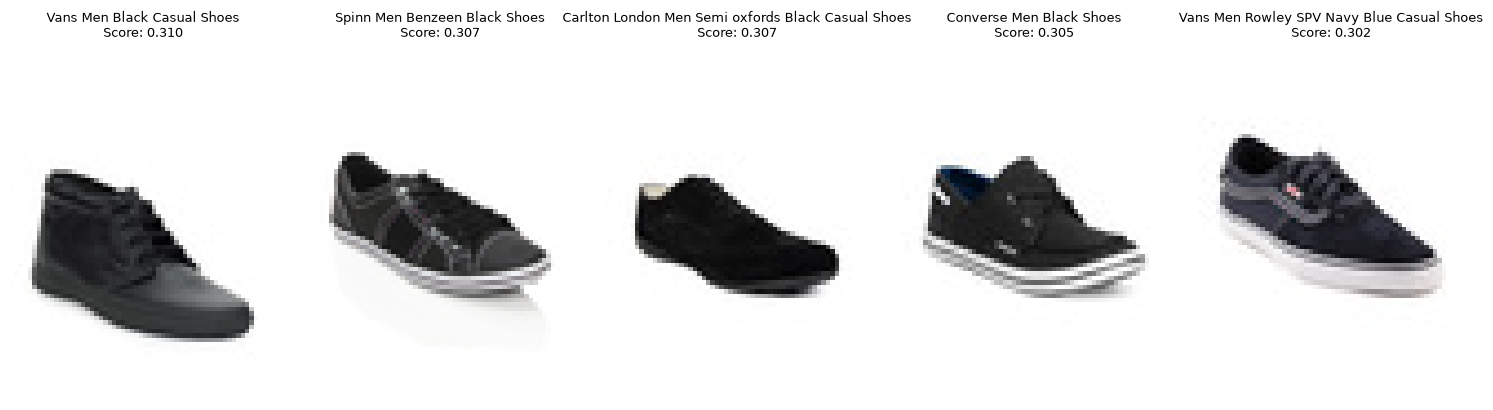

In [29]:
show_search_results(results)

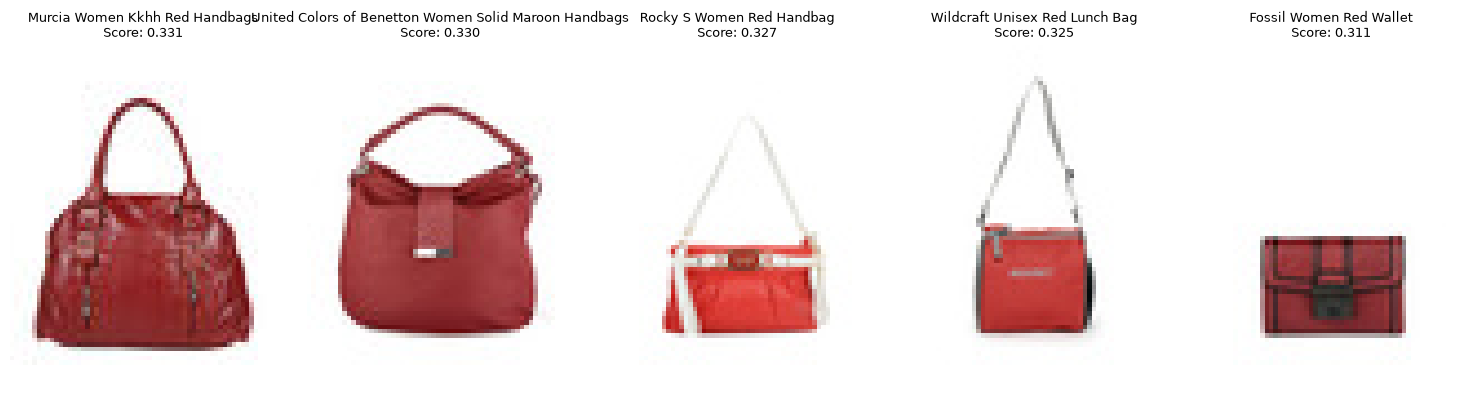

In [30]:
results = search_products(
    "red women's handbag",
    top_k=5
)

show_search_results(results)

In [31]:
def get_image_embedding(image_path):

    image = Image.open(image_path).convert("RGB")

    inputs = clip_processor(
        images=image,
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.inference_mode():

        vision_outputs = clip_model.vision_model(
            pixel_values=pixel_values
        )

        pooled_output = vision_outputs.pooler_output

        embedding = clip_model.visual_projection(
            pooled_output
        )

        embedding = embedding / embedding.norm(
            dim=-1,
            keepdim=True
        )

    return embedding.cpu().numpy()

In [32]:
def search_by_image(image_path, top_k=5):

    query_embedding = get_image_embedding(
        image_path
    )

    similarities = (
        image_embeddings_1000
        @ query_embedding.T
    ).squeeze()

    top_indices = (
        similarities.argsort()[::-1]
    )

    # Skip the first result if it is the
    # exact same image
    results_indices = top_indices[:top_k + 1]

    results = df_subset_valid.iloc[
        results_indices
    ].copy()

    results["similarity"] = similarities[
        results_indices
    ]

    return results

Query product: Quechua Women Maroon Cap


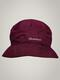

In [33]:
query_product = df_subset_valid.iloc[50]
query_image_path = query_product["image_path"]

print(
    "Query product:",
    query_product["productDisplayName"]
)

Image.open(query_image_path)

In [34]:
def search_by_image(image_path, top_k=5):

    query_embedding = get_image_embedding(
        image_path
    )

    similarities = (
        image_embeddings_1000
        @ query_embedding.T
    ).squeeze()

    top_indices = similarities.argsort()[::-1]

    # Remove the exact query image
    filtered_indices = []

    for idx in top_indices:

        candidate_path = df_subset_valid.iloc[idx]["image_path"]

        if str(candidate_path) != str(image_path):
            filtered_indices.append(idx)

        if len(filtered_indices) == top_k:
            break

    results = df_subset_valid.iloc[
        filtered_indices
    ].copy()

    results["similarity"] = similarities[
        filtered_indices
    ]

    return results

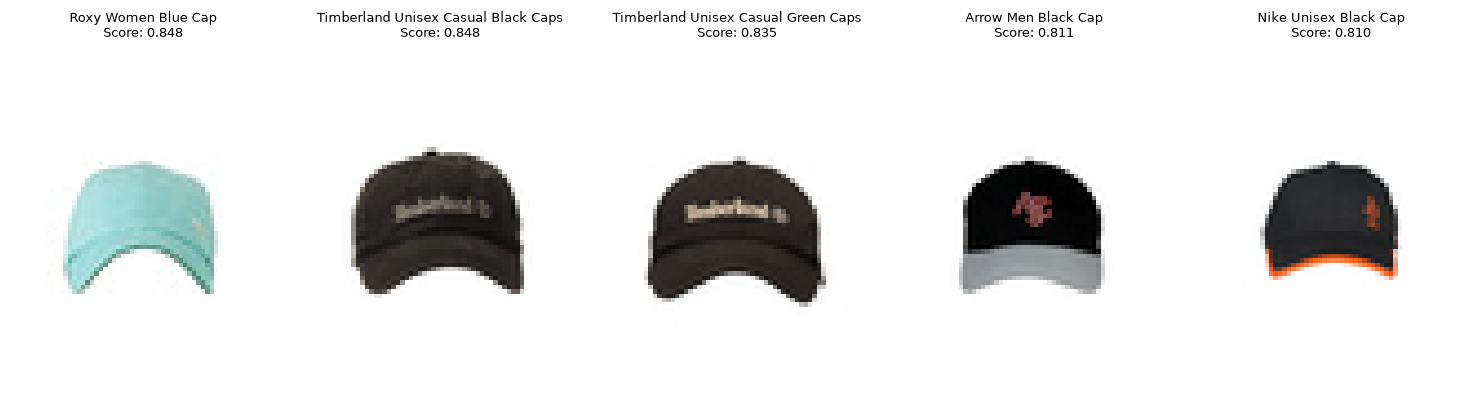

In [35]:
image_results = search_by_image(
    query_image_path,
    top_k=5
)

show_search_results(image_results)

In [36]:
df_full = df_products.reset_index(drop=True).copy()

print("Total products:", len(df_full))

Total products: 44419


In [37]:
df_full = df_products.sample(
    n=10000,
    random_state=42
).reset_index(drop=True)

print("Products selected:", len(df_full))

Products selected: 10000


In [38]:
import numpy as np
from tqdm.auto import tqdm

batch_size = 32

all_embeddings = []
valid_indices = []

for start in tqdm(range(0, len(df_full), batch_size)):

    batch_df = df_full.iloc[start:start + batch_size]

    images = []
    batch_indices = []

    for idx, row in batch_df.iterrows():

        try:
            image = Image.open(
                row["image_path"]
            ).convert("RGB")

            images.append(image)
            batch_indices.append(idx)

        except Exception as e:
            print(f"Skipping {row['image_path']}: {e}")

    if len(images) == 0:
        continue

    inputs = clip_processor(
        images=images,
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.inference_mode():

        vision_outputs = clip_model.vision_model(
            pixel_values=pixel_values
        )

        pooled_output = vision_outputs.pooler_output

        embeddings = clip_model.visual_projection(
            pooled_output
        )

        embeddings = embeddings / embeddings.norm(
            dim=-1,
            keepdim=True
        )

    all_embeddings.append(
        embeddings.cpu().numpy()
    )

    valid_indices.extend(batch_indices)

  0%|          | 0/313 [00:00<?, ?it/s]

In [39]:
image_embeddings_full = np.vstack(
    all_embeddings
)

df_full_valid = df_full.loc[
    valid_indices
].reset_index(drop=True)

print(
    "Full embedding shape:",
    image_embeddings_full.shape
)

print(
    "Products with embeddings:",
    len(df_full_valid)
)

Full embedding shape: (10000, 512)
Products with embeddings: 10000


In [40]:
np.save(
    "../embeddings/image_embeddings_10000.npy",
    image_embeddings_full
)

df_full_valid.to_csv(
    "../embeddings/products_10000.csv",
    index=False
)

print("10,000 product catalog saved successfully")

10,000 product catalog saved successfully


In [41]:
import numpy as np
import pandas as pd

image_embedding_10000 = np.load(
    "../embeddings/image_embeddings_10000.npy"
)

df_products_10000 = pd.read_csv(
    "../embeddings/products_10000.csv"
)

print("Embedding shape:", image_embedding_10000.shape)
print("Products:", len(df_products_10000))

Embedding shape: (10000, 512)
Products: 10000


In [43]:
def search_products_10000(query, top_k=5):
    text_inputs = clip_processor(
        text=[query],
        padding=True,
        return_tensors="pt"
    )

    input_ids = text_inputs["input_ids"].to(device)
    attention_mask = text_inputs["attention_mask"].to(device)

    with torch.inference_mode():
        text_outputs = clip_model.text_model(
            input_ids = input_ids,
            attention_mask = attention_mask
        )

        pooled_text = text_outputs.pooler_output

        text_embeddings = clip_model.text_projection(
            pooled_text
        )

        text_embeddings = text_embeddings / text_embeddings.norm(
            dim=-1,
            keepdim=True
        )

    text_embeddings = text_embeddings.cpu().numpy()

    similarities = (
        image_embedding_10000
        @ text_embeddings.T 
    ).squeeze()

    top_indices = similarities.argsort()[::-1][:top_k]

    results = df_products_10000.iloc[
        top_indices
    ].copy()

    results["similarity"] = similarities[
        top_indices
    ]

    return results

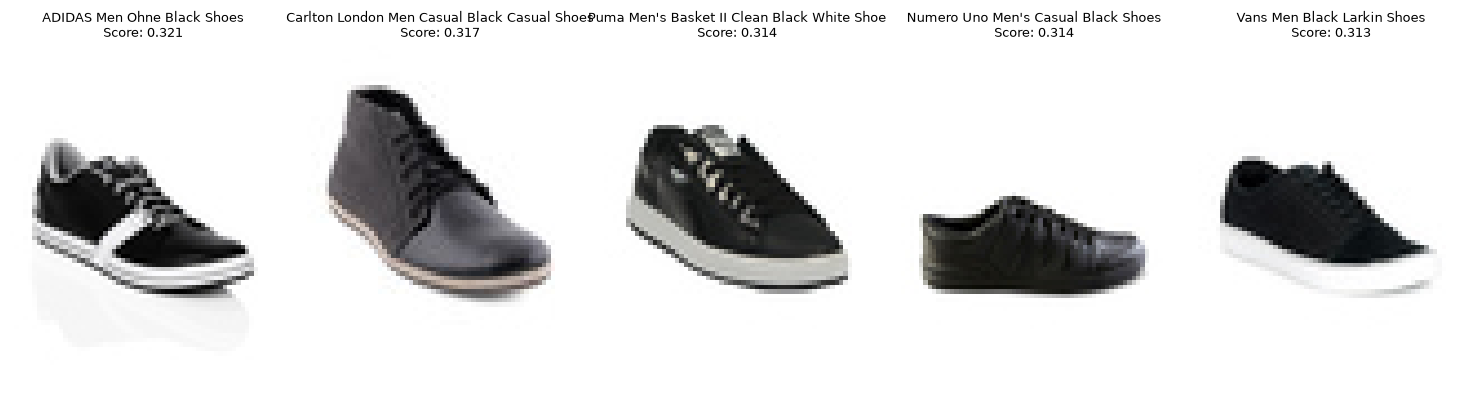

In [44]:
results = search_products_10000(
    "black casual shoes",
    top_k=5
)

show_search_results(results)

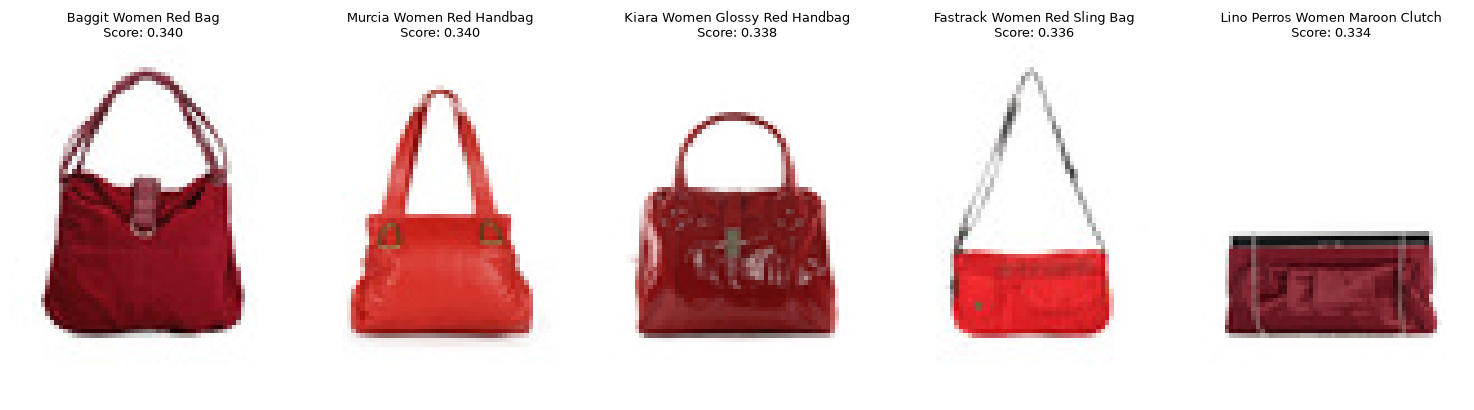

In [45]:
results = search_products_10000(
    "red women's handbag",
    top_k=5
)

show_search_results(results)

In [1]:
def search_by_image_10000(image_path, top_k=5):
     query_embedding = get_image_embedding(
          image_path
     )

     similarities = (
          image_embedding_10000
          @ query_embedding.T
     ).squeeze()

     top_indices = similarities.argsort()[::-1]
     filtered_indices = []

     for idx in top_indices:
          candidate_path = df_products_10000.iloc[idx]["image_path"]

          if str(candidate_path) != str(image_path):
               filtered_indices.append(idx)

          if len(filtered_indices) == top_k:
               break

     results = df_products_10000.iloc[
          filtered_indices
     ].copy()

     results["similarity"] = similarities[
          filtered_indices
     ]

     return results 
        

In [3]:
# ==========================================
# StyleMatch AI - Resume / Startup Cell
# ==========================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from transformers import CLIPModel, CLIPProcessor


# -------------------------
# 1. Device
# -------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# -------------------------
# 2. Load CLIP
# -------------------------

model_name = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(
    model_name
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    model_name
)

clip_model.eval()

print("CLIP loaded")


# -------------------------
# 3. Load saved embeddings
# -------------------------

image_embeddings_10000 = np.load(
    "../embeddings/image_embeddings_10000.npy"
)

df_products_10000 = pd.read_csv(
    "../embeddings/products_10000.csv"
)

print(
    "Embeddings:",
    image_embeddings_10000.shape
)

print(
    "Products:",
    len(df_products_10000)
)

Device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded
Embeddings: (10000, 512)
Products: 10000


Query product: Ray-Ban Men Shiny Hawana Black Sunglasses


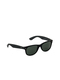

In [4]:
query_product = df_products_10000.iloc[100]

query_image_path = query_product["image_path"]

print(
    "Query product:",
    query_product["productDisplayName"]
)

Image.open(query_image_path)

In [8]:
print("Gender values:")
print(df_products_10000["gender"].value_counts())

print("\nCategories:")
print(df_products_10000["masterCategory"].value_counts())

print("\nUsage:")
print(df_products_10000["usage"].value_counts())

Gender values:
gender
Men       4991
Women     4189
Unisex     495
Boys       183
Girls      142
Name: count, dtype: int64

Categories:
masterCategory
Apparel           4805
Accessories       2559
Footwear          2048
Personal Care      564
Free Items          20
Sporting Goods       3
Home                 1
Name: count, dtype: int64

Usage:
usage
Casual          7755
Sports           894
Ethnic           707
Formal           549
Smart Casual      13
Party              9
Travel             7
Home               1
Name: count, dtype: int64


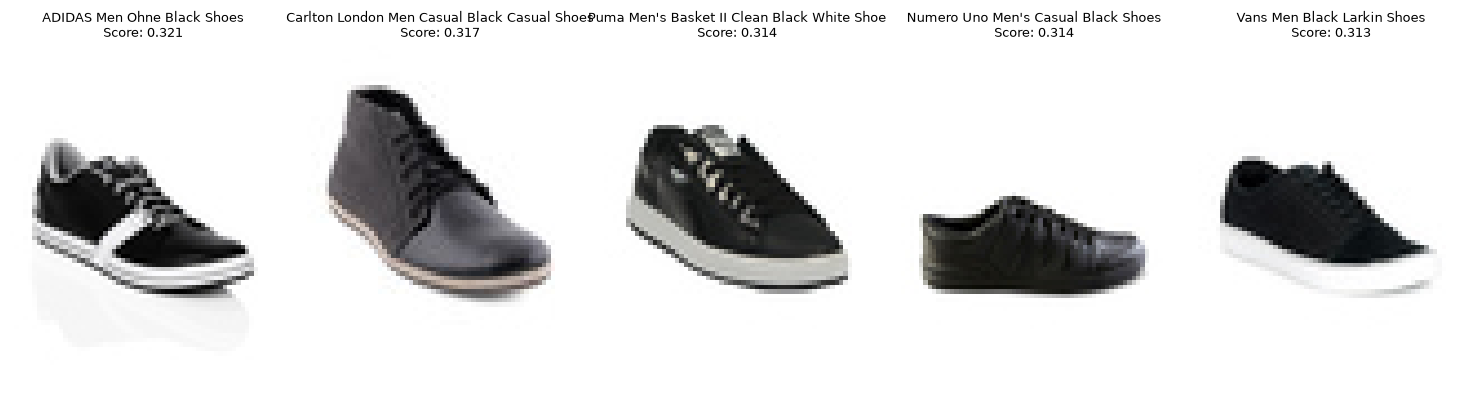

In [5]:
results = search_products_filtered(
    query="black casual shoes",
    clip_model=clip_model,
    clip_processor=clip_processor,
    device=device,
    image_embeddings=image_embeddings_10000,
    products_df=df_products_10000,
    top_k=5,
    gender="Men",
    category="Footwear"
)

show_search_results(results)

In [7]:
import importlib
import src.search_engine as search_engine

importlib.reload(search_engine)

from src.search_engine import (
    search_products,
    search_products_filtered,
    search_by_image,
    show_search_results
)

print("search_engine.py reloaded")

search_engine.py reloaded


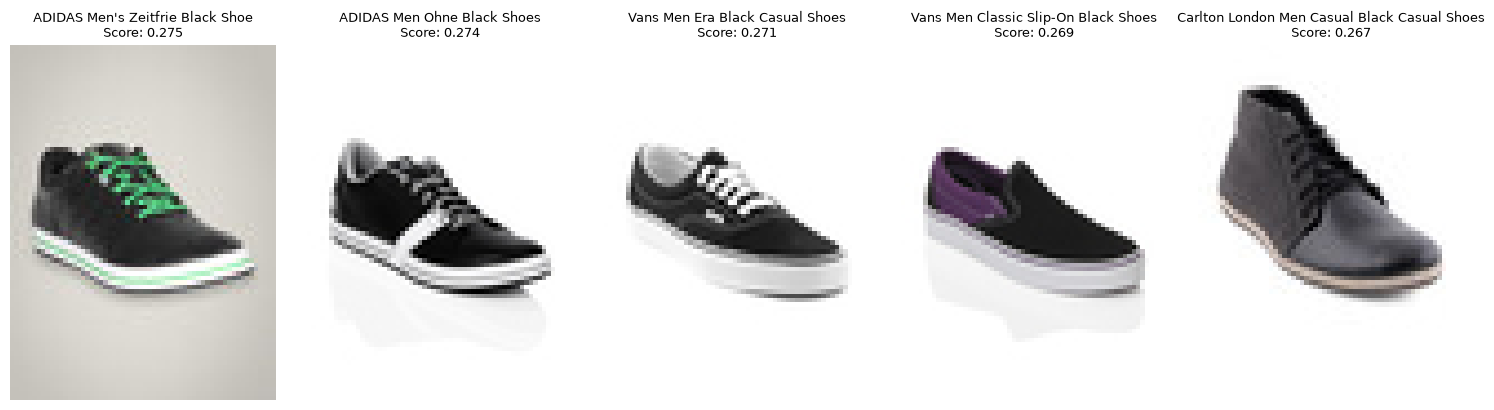

In [8]:
results = search_products_filtered(
    query="casual shoes",
    clip_model=clip_model,
    clip_processor=clip_processor,
    device=device,
    image_embeddings=image_embeddings_10000,
    products_df=df_products_10000,
    top_k=5,
    gender="Men",
    category="Footwear",
    colour="Black",
    usage="Casual"
)

show_search_results(results)

In [9]:
from pathlib import Path
import pandas as pd
import shutil


# Project paths
project_root = Path("..").resolve()

source_images = project_root / "data" / "images"
catalog_images = project_root / "data" / "catalog_images"

products_file = (
    project_root
    / "embeddings"
    / "products_10000.csv"
)


# Create destination folder
catalog_images.mkdir(
    parents=True,
    exist_ok=True
)


# Load the 10k catalog
products = pd.read_csv(products_file)

copied = 0
missing = 0


for product_id in products["id"]:

    product_id = int(product_id)

    source = (
        source_images
        / f"{product_id}.jpg"
    )

    destination = (
        catalog_images
        / f"{product_id}.jpg"
    )

    if source.exists():

        shutil.copy2(
            source,
            destination
        )

        copied += 1

    else:

        missing += 1


print("Images copied:", copied)
print("Missing images:", missing)
print("Saved to:", catalog_images)

Images copied: 10000
Missing images: 0
Saved to: C:\Users\swanz\OneDrive\Desktop\stylematch-AI\data\catalog_images
